In [135]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV
from sklearn.model_selection import StratifiedKFold
from sklearn.compose import ColumnTransformer


In [136]:
data = pd.read_csv('trainCA4DAT200.csv')
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 3500 entries, 0 to 3499
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   CustomerId            3500 non-null   int64  
 1   State                 3500 non-null   str    
 2   AccountLength         3500 non-null   int64  
 3   AreaCode              3500 non-null   int64  
 4   InternationalPlan     3500 non-null   str    
 5   VoiceMailPlan         3500 non-null   str    
 6   NumVoiceMailMessages  3500 non-null   int64  
 7   DayMinutes            3500 non-null   float64
 8   DayCalls              3500 non-null   int64  
 9   DayCharge             3500 non-null   float64
 10  EveMinutes            3500 non-null   float64
 11  EveCalls              3500 non-null   int64  
 12  EveCharge             3500 non-null   float64
 13  NightMinutes          3500 non-null   float64
 14  NightCalls            3500 non-null   int64  
 15  NightCharge           3500 non-n

In [137]:
data_featselec = data.copy()

data_featselec['HasCustomerCalls'] = (data_featselec['CustomerServiceCalls'] > 0).astype(int)
data_featselec['ManyCustomerCalls'] = (data_featselec['CustomerServiceCalls'] >= 3).astype(int)

data_featselec['AccountLengthBin'] = pd.cut(data_featselec['AccountLength'], bins=[1, 30, 90, 180, float('inf')], labels=['new', 'medium', 'long', 'very_long'])
data_featselec = pd.get_dummies(data_featselec, columns=['AccountLengthBin'], drop_first=True)

data_featselec['TotalCharge'] = data_featselec['DayCharge'] + data_featselec['EveCharge'] + data_featselec['NightCharge'] + data_featselec['IntlCharge']

data_featselec['IntlChargeShare'] = data_featselec['IntlCharge'] / data_featselec['TotalCharge'].replace(0, np.nan)  # Avoid division by zero

data_featselec['InternationalPlan'] = data_featselec['InternationalPlan'].map({'yes': 1, 'no': 0})
data_featselec['VoiceMailPlan'] = data_featselec['VoiceMailPlan'].map({'yes': 1, 'no': 0})

In [138]:
data_clean = pd.get_dummies(data_featselec, columns=['State', 'AreaCode'], drop_first=True, dtype=int)
data_clean.isnull().sum().sum()

np.int64(0)

In [139]:
data_clean['TotalMinutes'] = data_clean['DayMinutes'] + data_clean['EveMinutes'] + data_clean['NightMinutes'] + data_clean['IntlMinutes']
data_clean['TotalCalls'] = data_clean['DayCalls'] + data_clean['EveCalls'] + data_clean['NightCalls'] + data_clean['IntlCalls']

In [140]:
#X = data_clean.drop(columns=['CustomerId', 'Churn', 'TotalMinutes', 'TotalCalls', 'DayChargeRatio', 'EveChargeRatio', 'NightChargeRatio']).copy()
y = data_clean['Churn'].copy()
X = data_clean[['AccountLength', 'InternationalPlan', 'VoiceMailPlan',
       'NumVoiceMailMessages', 'DayMinutes', 'DayCalls', 'DayCharge',
       'EveMinutes', 'EveCalls', 'EveCharge', 'NightMinutes', 'NightCalls',
       'NightCharge', 'IntlMinutes', 'IntlCalls', 'IntlCharge',
       'CustomerServiceCalls', 'HasCustomerCalls',
       'ManyCustomerCalls', 'AccountLengthBin_medium', 'AccountLengthBin_long',
       'AccountLengthBin_very_long', 'TotalCharge', 'IntlChargeShare', 'AreaCode_415', 'AreaCode_510', 'TotalMinutes',
       'TotalCalls']].copy()
X.nunique()

AccountLength                  211
InternationalPlan                2
VoiceMailPlan                    2
NumVoiceMailMessages            45
DayMinutes                    1689
DayCalls                       118
DayCharge                     1689
EveMinutes                    1631
EveCalls                       120
EveCharge                     1455
NightMinutes                  1616
NightCalls                     129
NightCharge                    944
IntlMinutes                    162
IntlCalls                       20
IntlCharge                     162
CustomerServiceCalls            10
HasCustomerCalls                 2
ManyCustomerCalls                2
AccountLengthBin_medium          2
AccountLengthBin_long            2
AccountLengthBin_very_long       2
TotalCharge                   2797
IntlChargeShare               3465
AreaCode_415                     2
AreaCode_510                     2
TotalMinutes                  2636
TotalCalls                     199
dtype: int64

In [141]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42, stratify=y)

In [142]:
# Identify numerical features with more than two unique values
nunique = X_train.nunique()
num_cols = nunique[nunique > 2].index.tolist()

In [143]:
# Standardize numerical features while keeping the remaining features unchanged
preprocessor = ColumnTransformer(
    [("num", StandardScaler(), num_cols)],
    remainder="passthrough",
)

In [144]:
# Create a pipeline combining preprocessing and the SVM classifier
svm_pipeline = Pipeline([
    ("prep", preprocessor),
    ('svc', SVC(class_weight='balanced'))
])

# Define the hyperparameter values to evaluate
C_range = [1.0, 10.0, 100.0, 1000.0]
gamma_range = [0.001, 0.01, 0.1]

# Define separate parameter grids for each SVM kernel
param_grid_svm = [
    {
        'svc__kernel': ['linear'],
        'svc__C': C_range
    },
    {
        'svc__kernel': ['rbf'],
        'svc__C': C_range,
        'svc__gamma': gamma_range
    },
    {
        'svc__kernel': ['poly'],
        'svc__C': C_range,
        'svc__gamma': gamma_range,
        'svc__degree': [2, 3, 4]
    }
]

# Configure stratified cross-validation with four folds
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Perform grid search using macro F1 as the evaluation metric
svm_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid_svm,  
    scoring='f1_macro',
    n_jobs=-1,
    cv=skf
)

# Train and evaluate the different hyperparameter combinations
svm_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...'balanced'))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'svc__C': [1.0, 10.0, ...], 'svc__kernel': ['linear']}, {'svc__C': [1.0, 10.0, ...], 'svc__gamma': [0.001, 0.01, ...], 'svc__kernel': ['rbf']}, ...]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... ve

In [145]:
# Display the best hyperparameters and cross-validation score
print(svm_search.best_params_)
print(f' CrossValidation macro f1 score: {svm_search.best_score_}')

{'svc__C': 1.0, 'svc__gamma': 0.1, 'svc__kernel': 'rbf'}
 CrossValidation macro f1 score: 0.7890046719489828


In [146]:
# Retrieve the best pipeline found during grid search
best_svm_model = svm_search.best_estimator_

# Compare cross-validation performance with performance on the test set
cv_f1 = svm_search.best_score_
test_f1 = f1_score(y_test, best_svm_model.predict(X_test), average='macro')

print(f"CV macro F1:   {cv_f1:.4f}")
print(f"Test macro F1: {test_f1:.4f}")

CV macro F1:   0.7890
Test macro F1: 0.7985


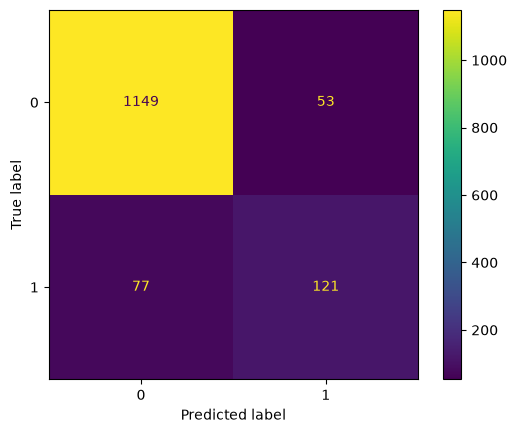

In [147]:
# Generate predictions for the test set
y_pred_svm = best_svm_model.predict(X_test)

# Plot the confusion matrix using raw counts
mat_conf = confusion_matrix(y_test, y_pred_svm)
vis = ConfusionMatrixDisplay(confusion_matrix=mat_conf)
vis.plot();

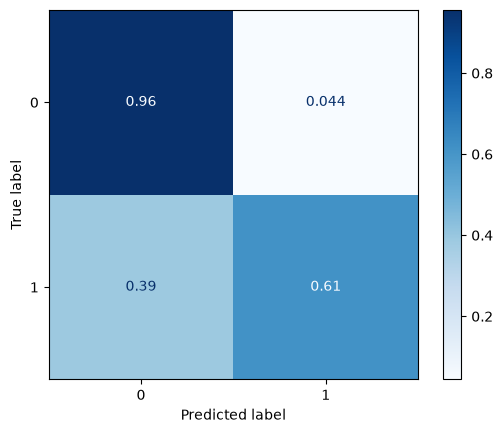

In [148]:
# Plot the normalized confusion matrix to compare classification rates
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_svm, normalize='true', cmap='Blues');

In [149]:
# Generate and display precision, recall, F1-score and support for each class
report = classification_report(y_test, y_pred_svm)
print(f'Classification Report:\n{report}')

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.96      0.95      1202
           1       0.70      0.61      0.65       198

    accuracy                           0.91      1400
   macro avg       0.82      0.78      0.80      1400
weighted avg       0.90      0.91      0.90      1400

